# EfficientNet_04: EfficientNet-B0, grouped split (34 species, unseen recordings), 3 seeds

**Change vs 03: augmentation aimed at recording differences** (DL Lab 5: simulate the conditions you will meet).
* random low-pass (p 0.5): blank mel bins above a random cutoff → the "empty band = sample rate" shortcut stops working
* SpecAugment: 2 frequency masks (≤ 12 bins) + 2 time masks (≤ 40 frames)
* gaussian noise (p 0.5, std 0.05)
* random time offset: random 400-frame window / random position of short clips
No frequency flips or shifts (they change the call).

Everything else is the 2025 recipe (see `EfficientNet_02.ipynb`). **Selection rule:** runs are compared on mean
*validation* macro-F1 over seeds 42/43/44; test metrics are recorded but not used for choosing.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src import config
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

GPU: NVIDIA GeForce RTX 5050 Laptop GPU


In [2]:
from src.EfficientNet.experiment import run_seeds
RUN = "EfficientNet_04"
df = run_seeds(RUN, split="grouped", augment=True, lr=1e-4, weight_decay=1e-2, max_epochs=15, patience=4)
df

device=cuda | classes=34 | train=9502 val=2102 test=2057


Epoch 1/15 | train loss 2.4656 acc 44.63 | val loss 2.8009 acc 24.41 | lr 1.00e-04 | 186s


  saved best checkpoint -> efficientnet_04_s42_best_01.pth


Epoch 2/15 | train loss 1.1967 acc 71.97 | val loss 3.0540 acc 31.16 | lr 1.00e-04 | 59s


Epoch 3/15 | train loss 0.7537 acc 80.37 | val loss 3.2239 acc 34.40 | lr 1.00e-04 | 54s


Epoch 4/15 | train loss 0.5362 acc 85.41 | val loss 3.7305 acc 36.77 | lr 1.00e-04 | 60s


... (21 outputs left out)

  early stopping (no val-loss improvement for 4 epochs)


Training finished.


--> EfficientNet_04_s44: val F1 0.183 acc 0.272 | best epoch 1/5


,run,seed,split,config,best_epoch,epochs_run,val_loss,val_acc,val_f1_macro,test_acc,test_f1_macro,minutes
0,EfficientNet_04,42,grouped,"{""augment"": true, ""lr"": 0.0001, ""weight_decay""...",1,5,2.8009,0.2441,0.1555,0.4317,0.2750,10.3
1,EfficientNet_04,43,grouped,"{""augment"": true, ""lr"": 0.0001, ""weight_decay""...",1,5,2.8098,0.2288,0.1477,0.3860,0.2602,4.8
2,EfficientNet_04,44,grouped,"{""augment"": true, ""lr"": 0.0001, ""weight_decay""...",1,5,2.7663,0.2716,0.1831,0.3831,0.2432,5.2


In [3]:
df[["val_f1_macro", "val_acc", "test_f1_macro", "test_acc", "best_epoch"]].agg(["mean", "std"]).round(3)

,val_f1_macro,val_acc,test_f1_macro,test_acc,best_epoch
mean,0.162,0.248,0.259,0.400,1.0
std,0.019,0.022,0.016,0.027,0.0


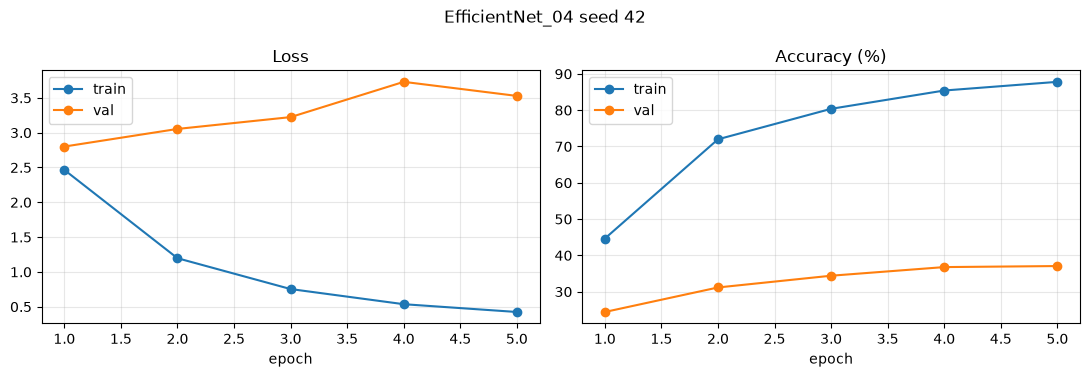

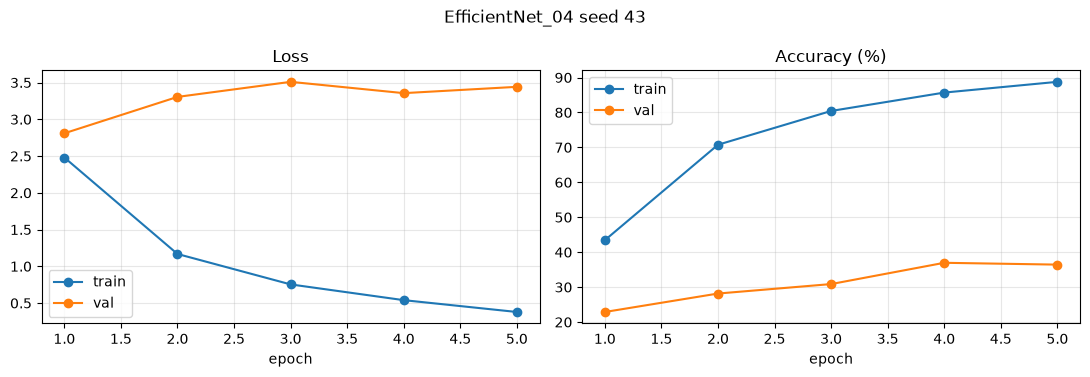

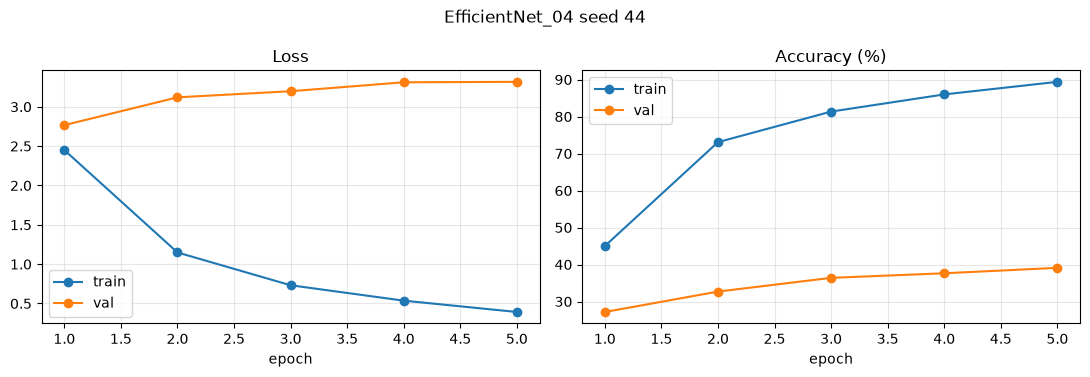

In [4]:
from src.plot_analysis import plot_learning_curves
import matplotlib.pyplot as plt
for s in df.seed:
    h = sorted(config.MODELS_OUTPUT.glob(f"{RUN.lower()}_s{s}_best_*_training_history.csv"))[-1]
    plot_learning_curves(h, f"{RUN} seed {s}", config.EVAL_DIR / f"learning_curves_{RUN}_s{s}.png"); plt.show()